# Part 1B: MACE Reproduction

**Paper:** Montori et al., "A Metadata-Assisted Cascading Ensemble Classification Framework for Automatic Annotation of Open IoT Data", IEEE Internet of Things Journal, 10(15), 2023


In this notebook, I reproduce every experiment in Section V of the paper with the same data, features and split (stratified 70:30, seed 100) and the classifier settings from the authors' released code. It contains nine experiments (Exp5 to Exp13) that share one cached reproduction so each model is fitted once


## Setup

In [1]:
# load the shared experiment and plotting functions
from pathlib import Path
import platform
import sys
import time
import warnings
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.linalg import LinAlgWarning
import seaborn as sns
import sklearn
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from mace.additionalExperiments import runErrorAnalysis, runTimeSeriesBaselines, runTunedBOS, saveTable
from mace.plotting import applyPlotStyle, plotHeuristicDistributions, plotPaperComparison, plotTopKPanels, saveFigure
from mace.reproductionPipeline import ddlNLPDiagnostic, runFullPaperReproduction

# logistic regression is fitted on unscaled features to match the authors' released code,
# so it does not converge on ThingSpeak; this is reported in the Exp5 findings
warnings.filterwarnings("ignore", category=ConvergenceWarning)
# ridge on unscaled features is ill-conditioned and ThingSpeak's rarest class has only 3 training streams
warnings.filterwarnings("ignore", category=LinAlgWarning)
warnings.filterwarnings("ignore", message="The least populated class in y", category=UserWarning)

applyPlotStyle()
INCLUDE_BRUTE_FORCE = True
INCLUDE_POOL_ANALYSIS = True

## Exp5: Standalone Bag-of-Summaries Classifiers

The eight classifiers use the same eleven unscaled Bag-of-Summaries features. Accuracy uses each estimator's own prediction rule while AUC uses aligned class scores

,Dataset,Classifier,PaperAccuracy,Accuracy,Precision,Recall,F1,AUC,BalancedAccuracy,WeightedF1,LogLoss,AccuracyDifference
0,UrbanObservatory,Ridge,45.6,48.8,37.8,34.8,31.2,88.6,34.8,41.3,2.4044,3.2
1,UrbanObservatory,SVM,60.6,60.9,38.6,43.3,39.3,97.8,43.3,53.9,0.7404,0.3
2,UrbanObservatory,kNN,83.8,86.2,80.5,81.2,79.9,95.5,81.2,86.1,2.3106,2.4
3,UrbanObservatory,LR,82.2,75.9,72.2,67.5,67.7,94.8,67.5,75.6,1.3307,-6.3
4,UrbanObservatory,C4.5,85.0,85.6,80.7,79.6,79.5,89.3,79.6,85.6,5.1846,0.6
5,UrbanObservatory,NB,79.1,75.6,67.1,74.7,68.5,96.5,74.7,73.9,2.2380,-3.5
6,UrbanObservatory,RF,88.1,91.2,89.3,88.3,88.2,98.9,88.3,91.3,0.4270,3.1
7,UrbanObservatory,GBoost,85.6,88.8,88.4,84.4,84.7,98.0,84.4,88.7,0.5614,3.2
8,Swissex,Ridge,36.5,47.1,43.9,38.6,37.0,81.5,38.6,38.9,2.0613,10.6
9,Swissex,SVM,43.3,49.0,47.3,40.6,37.6,90.5,40.6,38.7,1.2994,5.7


,Classifier,UrbObs Paper,UrbObs Mine,UrbObs Difference,Swissex Paper,Swissex Mine,Swissex Difference,TS Paper,TS Mine,TS Difference
0,Ridge,45.6,48.8,3.2,36.5,47.1,10.6,31.4,38.8,7.4
1,SVM,60.6,60.9,0.3,43.3,49.0,5.7,62.5,20.4,-42.1
2,kNN,83.8,86.2,2.4,71.2,74.0,2.8,71.0,73.9,2.9
3,LR,82.2,75.9,-6.3,65.4,51.9,-13.5,61.1,36.4,-24.7
4,C4.5,85.0,85.6,0.6,66.3,72.1,5.8,72.1,66.6,-5.5
5,NB,79.1,75.6,-3.5,72.1,70.2,-1.9,29.2,28.4,-0.8
6,RF,88.1,91.2,3.1,78.8,84.6,5.8,75.7,76.0,0.3
7,GBoost,85.6,88.8,3.2,75.0,80.8,5.8,73.5,72.1,-1.4


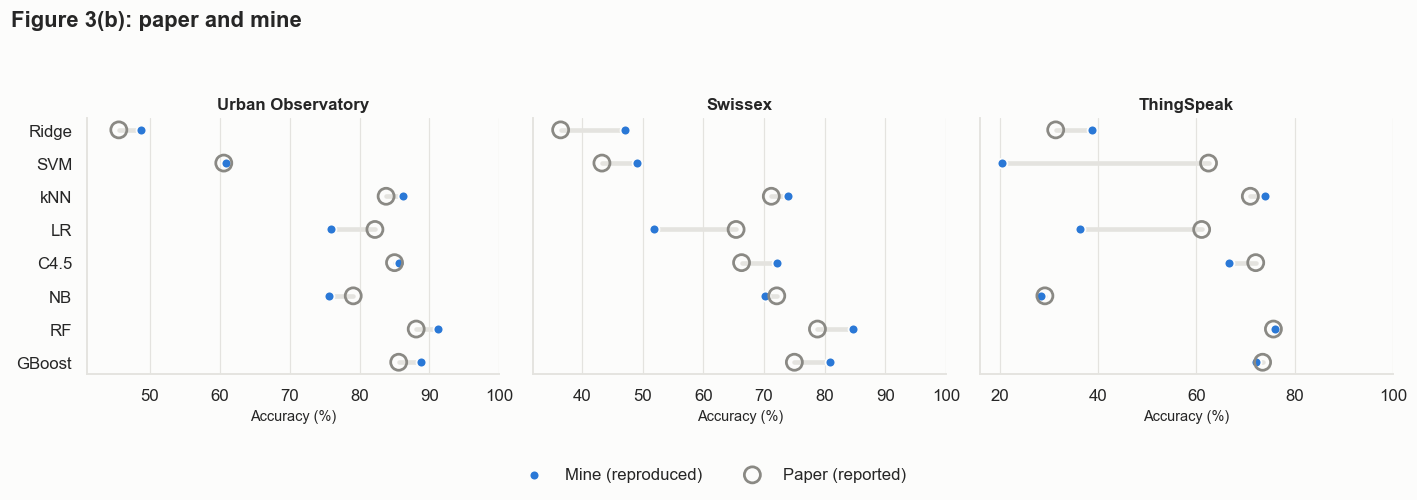

In [2]:
# execute the shared cached reproduction once for every later section
started = time.perf_counter()
results = runFullPaperReproduction(INCLUDE_BRUTE_FORCE, INCLUDE_POOL_ANALYSIS)
notebookRuntime = time.perf_counter() - started
display(results['standaloneBOS'])
display(results['figureThreeBComparison'])

datasetKeys = [('UrbObs', 'Urban Observatory'), ('Swissex', 'Swissex'), ('TS', 'ThingSpeak')]
figure = plotPaperComparison(results['figureThreeBComparison'], datasetKeys, 'Figure 3(b): paper and mine', 'Accuracy (%)')
saveFigure(figure, 'figure3bPaperVsMine')
plt.show()

### Findings

- Random Forest is the strongest BOS classifier on all three datasets (91.2, 84.6 and 76.0), matching the paper's ranking
- 18 of the 24 classifier and dataset pairs are within 6 points of the paper. The six larger gaps all involve Ridge, Logistic Regression or SVM, which are sensitive to feature scale
- SVM on ThingSpeak scores 20.4%, exactly the majority-class share: on unscaled features it predicts the largest class for every stream (macro recall 4.8%, i.e. 1 of 21 classes). The paper reports 62.5%
- Logistic Regression does not converge on the unscaled features and falls 6 to 25 points below the paper
- On Swissex every tree-based and kNN model is 3 to 6 points above the paper. Together with Exp11, this suggests the paper's Figure 3(b) came from a separate run with settings that were not released

## Exp6: Training-Only BOS Hyperparameter Optimisation

The paper describes the conventional classifiers as optimised but does not report complete grids. This extension uses stated grids and five-fold training cross-validation

In [3]:
# test the optimisation claim without using test labels
tunedBosTable = runTunedBOS(results['datasets'])
display(tunedBosTable)

,Dataset,Classifier,BestParameters,MeanCVAccuracy,Accuracy,Precision,Recall,F1,AUC,BalancedAccuracy,WeightedF1,LogLoss,FitSeconds
0,UrbanObservatory,Ridge,"{""estimator__alpha"": 0.1}",50.201342,48.8,37.8,34.8,31.2,88.6,34.8,41.3,2.4044,4.380486
1,UrbanObservatory,SVM,"{""C"": 10.0, ""gamma"": ""scale""}",73.825503,74.4,60.2,58.1,56.9,98.3,58.1,70.6,0.6385,1.068746
2,UrbanObservatory,kNN,"{""n_neighbors"": 7, ""weights"": ""distance""}",84.966443,87.8,83.0,82.7,81.8,95.9,82.7,87.6,2.0179,0.041097
3,UrbanObservatory,LR,"{""C"": 10.0}",75.570470,75.6,71.7,67.3,67.2,94.7,67.3,75.0,1.4035,0.818218
4,UrbanObservatory,C4.5,"{""max_depth"": null, ""min_samples_leaf"": 2}",86.577181,84.1,77.5,79.4,78.0,90.6,79.4,84.4,4.5376,0.084904
5,UrbanObservatory,NB,"{""var_smoothing"": 1e-11}",74.362416,75.9,68.0,75.3,69.1,96.5,75.3,74.2,2.2483,0.025830
6,UrbanObservatory,RF,"{""max_depth"": null, ""max_features"": ""sqrt""}",88.859060,91.2,89.3,88.3,88.2,98.9,88.3,91.3,0.4270,10.449624
7,UrbanObservatory,GBoost,"{""learning_rate"": 0.05, ""n_estimators"": 200}",87.114094,89.1,88.6,84.7,84.9,98.4,84.7,89.0,0.5412,24.944331
8,Swissex,Ridge,"{""estimator__alpha"": 0.1}",42.959184,47.1,43.9,38.6,37.0,81.5,38.6,38.9,2.0613,0.067350
9,Swissex,SVM,"{""C"": 10.0, ""gamma"": ""scale""}",54.532313,60.6,57.0,53.8,50.3,91.5,53.8,51.0,1.2203,0.480892


### Findings

- A training-only grid search lifts SVM on ThingSpeak from 20.4% to 68.1%, above the paper's 62.5% and on UrbObs from 60.9% to 74.4%. The paper's Figure 3(b) values therefore depend on tuned hyperparameters that are not in the released code
- Tuning cannot rescue Logistic Regression on ThingSpeak (36.4% before and after), because the problem is feature scale rather than regularisation strength
- Random Forest hardly changes (91.2 to 91.2, 84.6 to 84.6, 76.0 to 75.0) so the untuned RF inside the MACE pool is already close to its best
- Selection uses training folds only so these are valid test estimates

## Exp7: Time-Series Methods from Figure 3(a)

1NN-ED and 1NN-DTW are direct implementations. BOPF SDE and LTS are labelled as proxies when their unreleased construction cannot be recovered exactly. Runtime is reported beside performance

,Dataset,Method,Representation,Status,PaperAccuracy,Accuracy,Precision,Recall,F1,AUC,BalancedAccuracy,WeightedF1,LogLoss,FitSeconds,PredictionSeconds
0,UrbanObservatory,1NN-ED,raw,Exact available method,76.9,80.0,77.3,69.1,68.5,96.8,69.1,77.8,1.4372,0.000346,0.078935
1,UrbanObservatory,1NN-DTW,raw,Exact available method,90.0,89.7,83.0,81.7,81.9,98.8,81.7,89.4,1.0344,0.000074,107.331232
2,UrbanObservatory,1NN-DTW-band10,raw,Sensitivity (10% band),90.0,90.6,85.9,83.6,84.0,99.0,83.6,90.5,0.9911,0.000199,22.546715
3,UrbanObservatory,1NN-ED,znorm,Exact available method,67.2,70.0,60.0,60.0,56.8,95.5,60.0,69.7,2.1406,0.000244,0.073238
4,UrbanObservatory,1NN-DTW,znorm,Exact available method,81.6,80.3,73.0,71.9,71.1,94.8,71.9,81.1,1.8416,0.000064,107.410741
5,UrbanObservatory,1NN-DTW-band10,znorm,Sensitivity (10% band),81.6,82.8,77.1,73.7,73.4,96.6,73.7,83.6,1.7204,0.000222,23.062971
6,Swissex,1NN-ED,raw,Exact available method,55.8,58.7,57.7,56.3,55.3,90.7,56.3,59.9,1.4275,0.000251,0.004609
7,Swissex,1NN-DTW,raw,Exact available method,74.0,82.7,79.3,80.3,78.9,93.5,80.3,82.0,1.1248,0.000061,2.986210
8,Swissex,1NN-DTW-band10,raw,Sensitivity (10% band),74.0,77.9,75.4,74.7,73.5,92.9,74.7,77.1,1.1699,0.000064,0.677253
9,Swissex,1NN-ED,znorm,Exact available method,47.1,43.3,39.9,35.8,33.7,76.2,35.8,40.7,2.0000,0.000137,0.004101


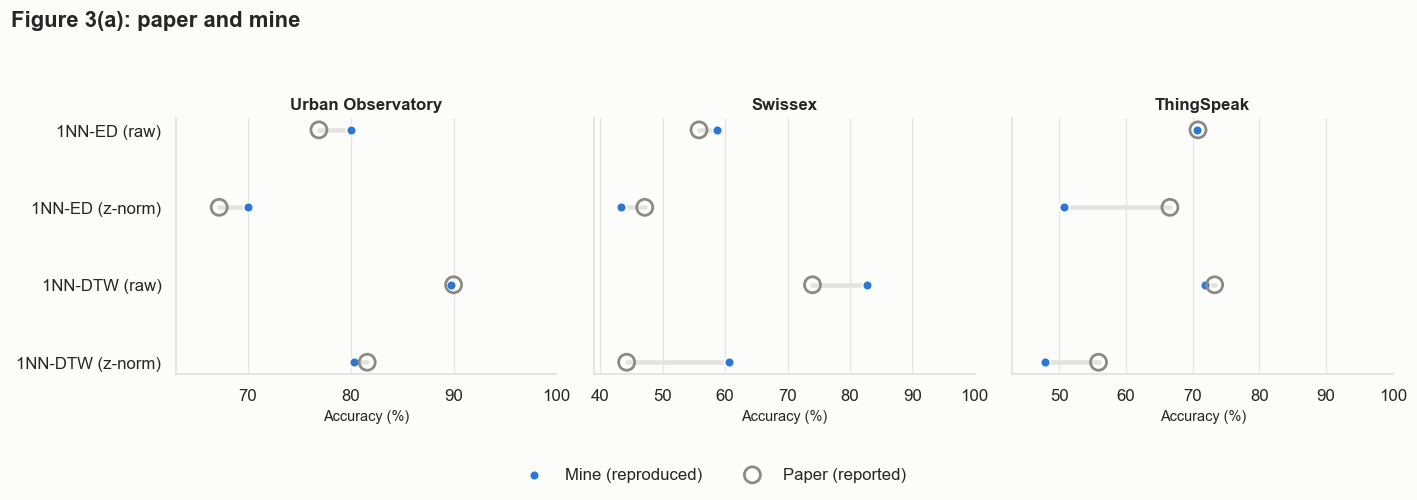

In [4]:
# evaluate raw and z-normalised time-series representations and show the exact methods first
timeSeriesTable = runTimeSeriesBaselines(results['datasets'])
exactMethods = ['1NN-ED', '1NN-DTW', '1NN-DTW-band10']
display(timeSeriesTable.loc[timeSeriesTable['Method'].isin(exactMethods)].reset_index(drop=True))

# compare the exact methods with Figure 3(a) in the same style as Figure 3(b)
figureRows = timeSeriesTable.loc[timeSeriesTable['Method'].isin(['1NN-ED', '1NN-DTW'])].copy()
figureRows['Method'] = figureRows['Method'] + ' (' + figureRows['Representation'].map({'raw': 'raw', 'znorm': 'z-norm'}) + ')'
figureRows['ShortName'] = figureRows['Dataset'].map({'UrbanObservatory': 'UrbObs', 'Swissex': 'Swissex', 'ThingSpeakEU': 'TS'})
methodOrder = ['1NN-ED (raw)', '1NN-ED (z-norm)', '1NN-DTW (raw)', '1NN-DTW (z-norm)']
paperWide = figureRows.pivot(index='Method', columns='ShortName', values='PaperAccuracy').reindex(methodOrder)
mineWide = figureRows.pivot(index='Method', columns='ShortName', values='Accuracy').reindex(methodOrder)
figureThreeAComparison = pd.concat([paperWide.add_suffix(' Paper'), mineWide.add_suffix(' Mine')], axis=1).reset_index()
figure = plotPaperComparison(figureThreeAComparison, datasetKeys, 'Figure 3(a): paper and mine', 'Accuracy (%)')
saveFigure(figure, 'figure3aPaperVsMine')
plt.show()

Proxies are feature-based stand-ins for unreleased algorithms and are not comparable to the paper.

In [5]:
# show the proxy stand-ins separately from the exact methods
display(timeSeriesTable.loc[~timeSeriesTable['Method'].isin(exactMethods)].reset_index(drop=True))

,Dataset,Method,Representation,Status,PaperAccuracy,Accuracy,Precision,Recall,F1,AUC,BalancedAccuracy,WeightedF1,LogLoss,FitSeconds,PredictionSeconds
0,UrbanObservatory,BOPF-Proxy,raw,Proxy,74.7,90.0,88.2,84.1,84.0,99.0,84.1,89.8,0.4561,0.223596,0.033802
1,UrbanObservatory,SDE-Proxy,raw,Proxy,47.2,57.8,42.3,41.7,39.8,88.8,41.7,53.2,1.9449,0.214034,0.036996
2,UrbanObservatory,LTS-Proxy,raw,Proxy,6.9,92.5,91.3,91.1,90.8,99.5,91.1,92.5,0.3025,0.436064,0.085712
3,UrbanObservatory,BOPF-Proxy,znorm,Proxy,75.3,78.8,73.8,62.9,65.5,96.9,62.9,76.6,0.8891,0.215039,0.033824
4,UrbanObservatory,SDE-Proxy,znorm,Proxy,36.2,61.3,48.5,47.4,45.8,90.8,47.4,59.2,1.9001,0.289823,0.038821
5,UrbanObservatory,LTS-Proxy,znorm,Proxy,26.2,81.6,70.5,67.4,68.4,98.3,67.4,80.3,0.6655,0.341753,0.085338
6,Swissex,BOPF-Proxy,raw,Proxy,37.4,79.8,78.0,75.0,74.3,93.8,75.0,77.3,1.6658,0.153802,0.028137
7,Swissex,SDE-Proxy,raw,Proxy,31.7,54.8,49.3,45.5,44.1,85.3,45.5,49.5,1.9499,0.157000,0.027268
8,Swissex,LTS-Proxy,raw,Proxy,13.5,78.8,76.9,75.1,74.5,97.4,75.1,77.2,0.6417,0.190111,0.045268
9,Swissex,BOPF-Proxy,znorm,Proxy,44.2,64.4,74.0,57.5,59.4,90.5,57.5,62.5,1.5282,0.168005,0.028380


### Findings

- The raw whole-series baselines match the paper closely: 1NN-ED 70.6 vs 70.8 and 1NN-DTW 71.9 vs 73.3 on ThingSpeak and 1NN-DTW 89.7 vs 90.0 on UrbObs
- The paper's claim holds that raw data beats z-normalised data for 1NN-ED and 1NN-DTW, on all three datasets (for example 70.6 vs 50.7 for 1NN-ED on ThingSpeak)
- Two gaps stand out. Swissex raw 1NN-DTW is 8.7 points above the paper.. the paper used an approximate fast DTW (its reference [36]) while I compute exact DTW. z-normalised ThingSpeak is about 16 points below.. the paper does not describe its z-normalisation and ThingSpeak's 49 constant series have zero variance
- Exact DTW is more than 1,000 times slower than 1NN-ED on UrbObs (over a minute and a half per prediction pass against under a tenth of a second), which supports the paper's decision to leave DTW out of the MACE pool. A 10% warping band is about four to five times faster with similar accuracy on UrbObs and ThingSpeak
- BOPF, SDE and LTS were never released so the proxy rows are not reproductions. The paper's LTS result on UrbObs (6.9%) is below the 19.9% majority-class baseline, which suggests that run failed

## Exp8: DDL-NLP Metadata Classifier

In [6]:
# separate exact-name evidence from unseen-name generalisation
ddlTable = saveTable(ddlNLPDiagnostic(results['datasets']['thingspeak']['prepared']), 'ddlNLPDiagnostic')
display(ddlTable)

,Classifier,PaperAccuracy,Accuracy,Precision,Recall,F1,AUC,BalancedAccuracy,WeightedF1,LogLoss,TestNamesSeenInTrain,AccuracyOnSeenNames,AccuracyOnUnseenNames
0,DDL-NLP,73.2,73.2,75.1,70.9,71.9,95.7,70.9,72.9,1.1813,55.3,79.8,64.9


### Findings

- DDL-NLP reproduces the paper exactly: 73.2%
- 55.3% of test stream names also appear verbatim in the training set. Accuracy is 79.8% on those and 64.9% on unseen names so part of the metadata signal is exact-name memorisation. Exp15 in notebook 3 tests whether this comes from channels shared between training and test

## Exp9: Five-Fold Top-k Accuracy Curves

All top-k curves come from the same five held-out training folds. Stable sorting preserves the authors' lower-class tie rule

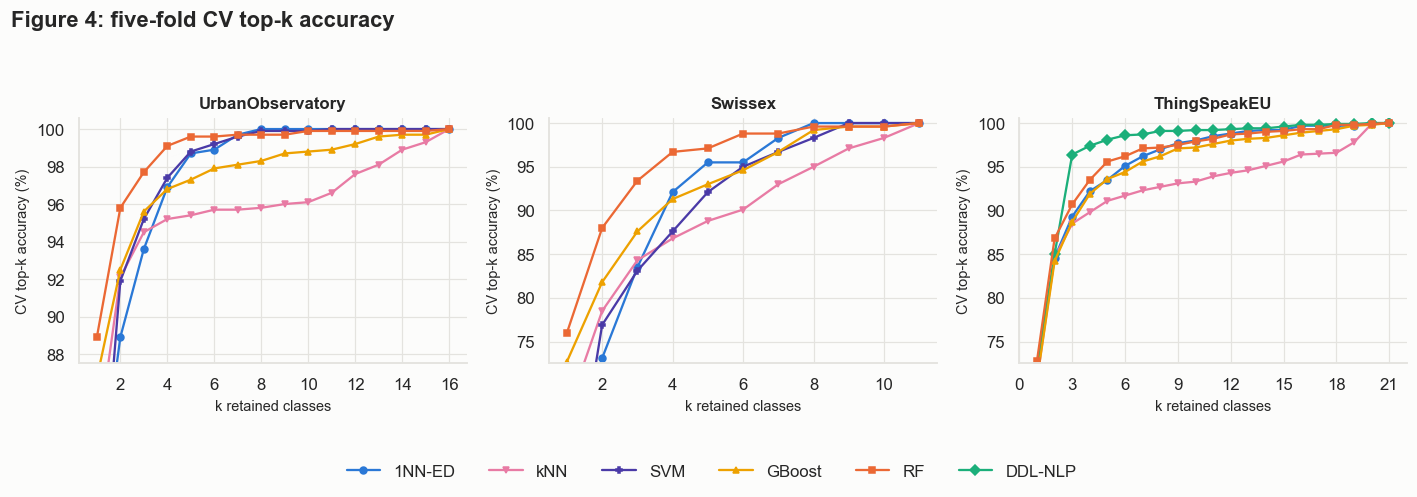

In [7]:
# show the Figure 4 curves from the shared training folds
figure = plotTopKPanels(results['topKCurves'], 'Figure 4: five-fold CV top-k accuracy')
saveFigure(figure, 'topKAccuracyCurves')
plt.show()

### Findings

- The curves have the same shape as the paper's Figure 4. On UrbObs, GBoost, kNN and SVM are dominated at every k, leaving 1NN-ED and RF, exactly as the paper describes
- On ThingSpeak, DDL-NLP dominates from k = 3 upward and RF below that so the metadata classifier is the natural front filter and RF the natural final classifier
- The Top-k value on UrbObs is 8 rather than the paper's 7 because RF and 1NN-ED tie at k = 7 and the released code keeps the previous winner on ties. The selected order is unaffected

## Exp10: Classifier Ordering and Cascade Parameter Tuning

The classifier order Top-k change points and SoF or PF settings are selected from the same five held-out training folds used for the Exp9 curves

In [8]:
# show the selected orders and parameters
display(results['heuristics'])
display(results['tuningCurves'])

,Dataset,ShortName,PaperOrder,ReproducedOrder,SameOrder,PaperTopK,ReproducedTopK,BestSigma,BestPercentage,BruteForceOrder,BruteForceSigma,BruteForceConfigurations,BruteForceSelectionProtocol,BruteForceValidForRecommendation
0,UrbanObservatory,UrbObs,1NN-ED > RF,1NN-ED > RF,True,7,"[8, 1]",-0.6,0.5,RF > 1NN-ED,1.0,2925,PaperOracle_TestOptimised,False
1,Swissex,Swissex,1NN-ED > RF,1NN-ED > RF,True,change points at k=10 and k=7,"[8, 1]",0.4,0.8,1NN-ED > RF > SVM > kNN,0.0,2925,PaperOracle_TestOptimised,False
2,ThingSpeakEU,TS,DDL-NLP > RF,DDL-NLP > RF,True,not stated,"[3, 1]",0.2,0.2,DDL-NLP > RF,-0.2,2925,PaperOracle_TestOptimised,False


,Dataset,Strategy,Parameter,CVAccuracy
0,UrbanObservatory,SoF,-0.6,88.86
1,UrbanObservatory,SoF,-0.4,88.86
2,UrbanObservatory,SoF,-0.2,88.86
3,UrbanObservatory,SoF,0.0,88.86
4,UrbanObservatory,SoF,0.2,88.72
5,UrbanObservatory,SoF,0.4,88.86
6,UrbanObservatory,SoF,0.6,88.72
7,UrbanObservatory,SoF,0.8,87.92
8,UrbanObservatory,SoF,1.0,87.79
9,UrbanObservatory,PF,0.1,79.46


### Findings

- The selected order matches the paper on all three datasets: 1NN-ED then RF on UrbObs and Swissex, DDL-NLP then RF on ThingSpeak
- On UrbObs the CV accuracy is almost flat across σ (87.8 to 88.9) so the SoF setting barely matters. On ThingSpeak it matters a lot: 73.1% at σ = -0.6 against 87.6% at the chosen σ = 0.2
- The brute-force configurations differ from the heuristic ones (for example RF before 1NN-ED on UrbObs), but they are chosen on test labels and are flagged as not valid for recommendation

## Exp11: Main MACE Reproduction of Tables I and II

The tables place every published checkpoint beside the current result and its signed difference. All five task metrics are kept in the complete metrics table

,Method,UrbObs Paper,UrbObs Mine,UrbObs Difference,Swissex Paper,Swissex Mine,Swissex Difference,TS Paper,TS Mine,TS Difference
0,Best standalone,88.1,91.2,3.1,78.8,84.6,5.8,75.7,76.0,0.3
1,Soft voting,89.1,90.6,1.5,83.7,81.7,-2.0,79.6,80.1,0.5
2,MACE Top-k,90.6,91.2,0.6,84.6,84.6,0.0,84.3,84.3,0.0
3,MACE PF,90.6,91.2,0.6,83.2,84.6,1.4,83.4,83.5,0.1
4,MACE SoF,90.6,91.2,0.6,82.7,82.7,0.0,88.2,88.5,0.3
5,MACE brute-force (SoF),92.2,92.5,0.3,86.5,86.5,0.0,88.5,89.0,0.5


,Method,UrbObs Paper,UrbObs Mine,UrbObs Difference,Swissex Paper,Swissex Mine,Swissex Difference,TS Paper,TS Mine,TS Difference
0,Best standalone,87.9,88.2,0.3,83.2,83.2,0.0,71.9,71.9,0.0
1,Soft voting,86.4,88.5,2.1,81.6,77.8,-3.8,57.8,58.8,1.0
2,MACE Top-k,87.9,88.2,0.3,83.2,83.2,0.0,67.7,67.6,-0.1
3,MACE PF,87.9,88.2,0.3,83.2,83.2,0.0,63.7,64.8,1.1
4,MACE SoF,87.9,88.2,0.3,80.0,80.0,0.0,79.4,79.4,0.0
5,MACE brute-force (SoF),88.7,89.8,1.1,84.0,83.9,-0.1,76.7,79.0,2.3


,Dataset,Method,Accuracy,Precision,Recall,F1,AUC,BalancedAccuracy,WeightedF1,LogLoss
0,UrbanObservatory,Best standalone,91.2,89.3,88.3,88.2,98.9,88.3,91.3,0.4270
1,UrbanObservatory,Soft voting,90.6,89.4,89.1,88.5,99.3,89.1,90.8,0.4850
2,UrbanObservatory,MACE Top-k,91.2,89.3,88.3,88.2,98.9,88.3,91.3,0.3730
3,UrbanObservatory,MACE PF,91.2,89.3,88.3,88.2,98.9,88.3,91.3,0.3730
4,UrbanObservatory,MACE SoF,91.2,89.3,88.3,88.2,98.7,88.3,91.3,0.3775
5,UrbanObservatory,MACE brute-force (SoF),92.5,91.0,89.5,89.8,97.3,89.5,92.4,1.4532
6,Swissex,Best standalone,84.6,83.0,84.0,83.2,97.2,84.0,84.4,0.6294
7,Swissex,Soft voting,81.7,81.0,77.3,77.8,97.1,77.3,80.9,0.7325
8,Swissex,MACE Top-k,84.6,83.0,84.0,83.2,97.2,84.0,84.4,0.6284
9,Swissex,MACE PF,84.6,83.0,84.0,83.2,97.2,84.0,84.4,0.6284


,Dataset,AccuracyClassifier,F1Classifier,AUCClassifier
0,UrbanObservatory,RF,RF,RF
1,Swissex,RF,RF,RF
2,ThingSpeakEU,RF,DDL-NLP,DDL-NLP


,Dataset,Method,FinalClassifier,IdenticalPredictions,SamplesChanged
0,UrbanObservatory,MACE Top-k,RF,100.0,0
1,UrbanObservatory,MACE PF,RF,100.0,0
2,UrbanObservatory,MACE SoF,RF,100.0,0
3,Swissex,MACE Top-k,RF,100.0,0
4,Swissex,MACE PF,RF,100.0,0
5,Swissex,MACE SoF,RF,94.2,6
6,ThingSpeakEU,MACE Top-k,RF,84.3,100
7,ThingSpeakEU,MACE PF,RF,85.9,90
8,ThingSpeakEU,MACE SoF,RF,80.7,123


,Dataset,SubPools,PaperAccuracy,FullPoolAccuracy,MinimumAccuracy,MedianAccuracy,MaximumAccuracy,PaperF1,FullPoolF1,MinimumF1,MedianF1,MaximumF1
0,UrbanObservatory,26,89.1,90.6,84.4,89.4,91.6,86.4,88.5,73.2,85.60,88.5
1,Swissex,26,83.7,81.7,67.3,80.8,84.6,81.6,77.8,62.6,77.45,82.2
2,ThingSpeakEU,26,79.6,80.1,73.3,80.4,87.1,57.8,58.8,47.8,59.20,77.4


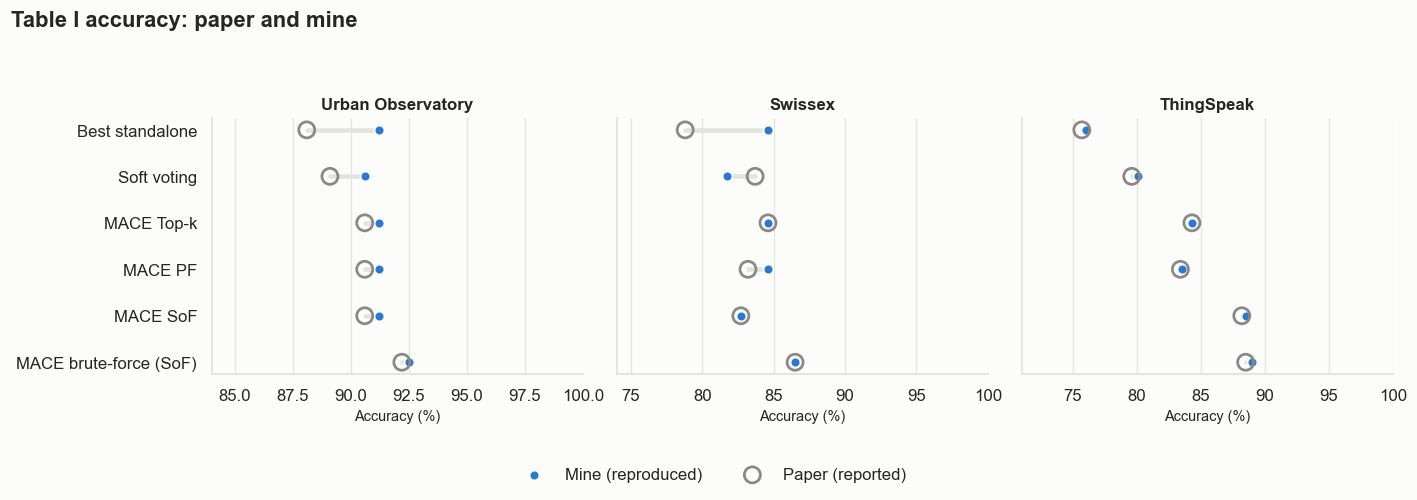

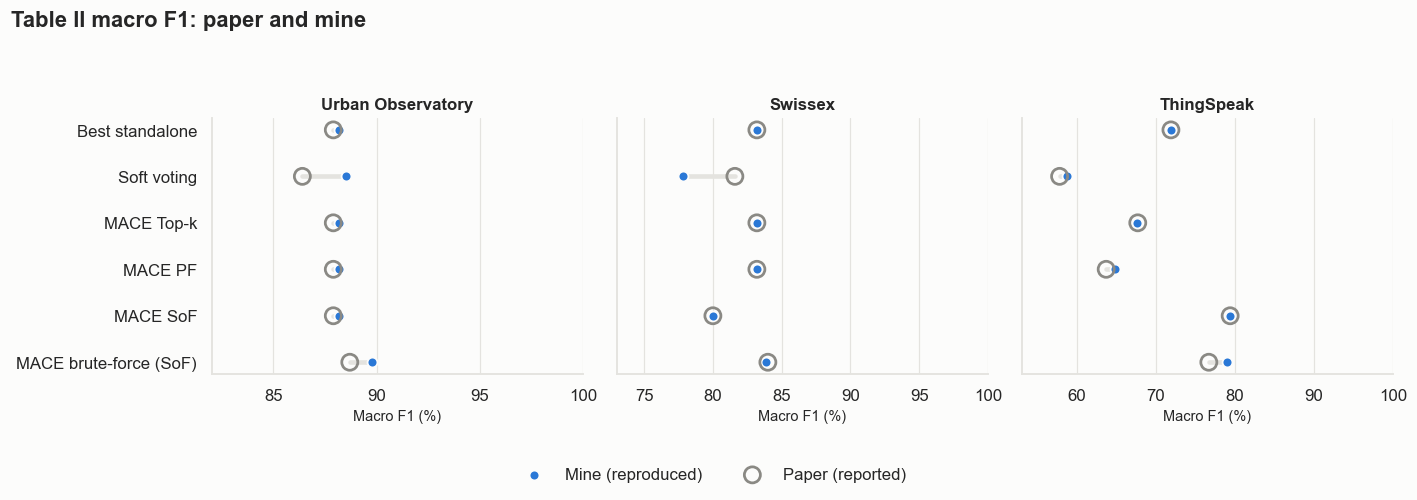

In [9]:
# display direct Paper versus Mine evidence for the main results
display(results['table1Accuracy'])
display(results['table2MacroF1'])
display(results['allMetrics'])
display(results['standaloneOrigins'])
display(results['maceVsFinal'])
display(results['votingSensitivity'])

accuracyFigure = plotPaperComparison(results['table1Accuracy'], datasetKeys, 'Table I accuracy: paper and mine', 'Accuracy (%)')
f1Figure = plotPaperComparison(results['table2MacroF1'], datasetKeys, 'Table II macro F1: paper and mine', 'Macro F1 (%)')
saveFigure(accuracyFigure, 'table1PaperVsMine')
saveFigure(f1Figure, 'table2PaperVsMine')
plt.show()
plt.show()

### Findings

- The MACE rows reproduce the paper closely. Accuracy is within 0.6 points in 8 of 9 cells (the exception is Swissex PF, +1.4) and macro F1 is within 0.3 points in 8 of 9, with four exact matches including the headline ThingSpeak SoF F1 of 79.4
- The "Best standalone" accuracy gap on UrbObs (+3.1) and Swissex (+5.8) is a paper inconsistency rather than a reproduction error. The paper's accuracies (88.1, 78.8, 75.7) equal its own Figure 3(b) RF bars while its F1 row matches the RF inside the MACE pool, which I reproduce exactly on Swissex (83.2) and within 0.3 on UrbObs
- On the single-domain datasets MACE adds nothing over its final classifier. Predictions are identical to RF alone for all three strategies on UrbObs and for Top-k and PF on Swissex.. SoF on Swissex changes 6 predictions and loses 1.9 points. On ThingSpeak the cascade changes 90 to 123 of 637 predictions and raises accuracy from 76.0% to 88.5%. The paper's claim that MACE beats every standalone classifier on all datasets therefore holds only on ThingSpeak
- Soft voting is the least stable row (-2.0 accuracy and -3.8 F1 on Swissex). The paper does not state the voting pool and across the 26 possible pools Swissex voting ranges from 67.3% to 84.6%, which contains the paper's 83.7%
- The brute-force row is a test-set oracle (the best of 2,925 configurations chosen on test labels) so it is an optimistic upper bound. The authors' own released notebook already prints a different ThingSpeak accuracy (88.7) from the paper (88.5)
- On ThingSpeak the best standalone accuracy comes from RF but the best standalone F1 from DDL-NLP so that row mixes two classifiers, as the standaloneOrigins table shows

## Exp12: Heuristic Evaluation Across 26 Classifier Pools

The paper's 2,925-configuration test oracle supplies the reference distribution. These plots show how Top-k PF and SoF compare across every starting pool without hiding weak configurations

NormalisedAccuracy                                \
                                         mean       std       min       max   
Dataset          Heuristic                                                    
Swissex          PF                  0.971537  0.022024  0.932584  1.000000   
                 SoF                 0.967662  0.023191  0.909091  1.000000   
                 Top-k               0.970073  0.032091  0.898876  1.000000   
ThingSpeakEU     PF                  0.933235  0.064863  0.827709  1.000000   
                 SoF                 0.950747  0.071537  0.827709  1.000000   
                 Top-k               0.934626  0.063955  0.827709  1.002119   
UrbanObservatory PF                  0.985703  0.014514  0.924188  1.000000   
                 SoF                 0.989535  0.009169  0.971831  1.000000   
                 Top-k               0.986256  0.012432  0.935018  1.000000   

                           OraclePercentile                               
                                       mean        std        min    max  
Dataset          Heuristic                                                
Swissex          PF               84.600030  16.650030  41.666667  100.0  
                 SoF              82.999493  18.249927  41.666667  100.0  
                 Top-k            83.983933  22.298296  30.370370  100.0  
ThingSpeakEU     PF               71.312178  24.466415  23.090278  100.0  
                 SoF              76.229468  29.017366  23.090278  100.0  
                 Top-k            68.114987  23.035172  23.090278  100.0  
UrbanObservatory PF               84.860919  18.190396  33.333333  100.0  
                 SoF              89.793701  15.538355  50.000000  100.0  
                 Top-k            84.320944  18.299867  36.111111  100.0

,Dataset,InputPool,SelectedOrder,VerbatimOrder,SelectedTopK,VerbatimTopK,SelectedTopkAccuracy,SelectedPFAccuracy,SelectedSoFAccuracy,VerbatimTopkAccuracy,VerbatimPFAccuracy,VerbatimSoFAccuracy
0,UrbanObservatory,1NN-ED | SVM,1NN-ED > SVM,1NN-ED > SVM > 1NN-ED,"[7, 1]","[7, 2, 1]",80.937500,80.000000,86.562500,82.812500,81.562500,82.187500
1,Swissex,1NN-ED | SVM,1NN-ED > SVM,1NN-ED > SVM > 1NN-ED,"[3, 1]","[3, 2, 1]",66.346154,66.346154,70.192308,61.538462,66.346154,71.153846
2,ThingSpeakEU,1NN-ED | kNN,1NN-ED > kNN,1NN-ED > kNN > 1NN-ED,"[3, 1]","[3, 2, 1]",74.725275,73.940345,75.353218,71.428571,73.940345,75.353218
3,ThingSpeakEU,1NN-ED | kNN | GBoost,kNN > GBoost > 1NN-ED,kNN > GBoost > 1NN-ED > kNN > 1NN-ED,"[20, 5, 1]","[20, 5, 3, 2, 1]",72.841444,73.155416,73.940345,73.469388,74.882261,72.527473


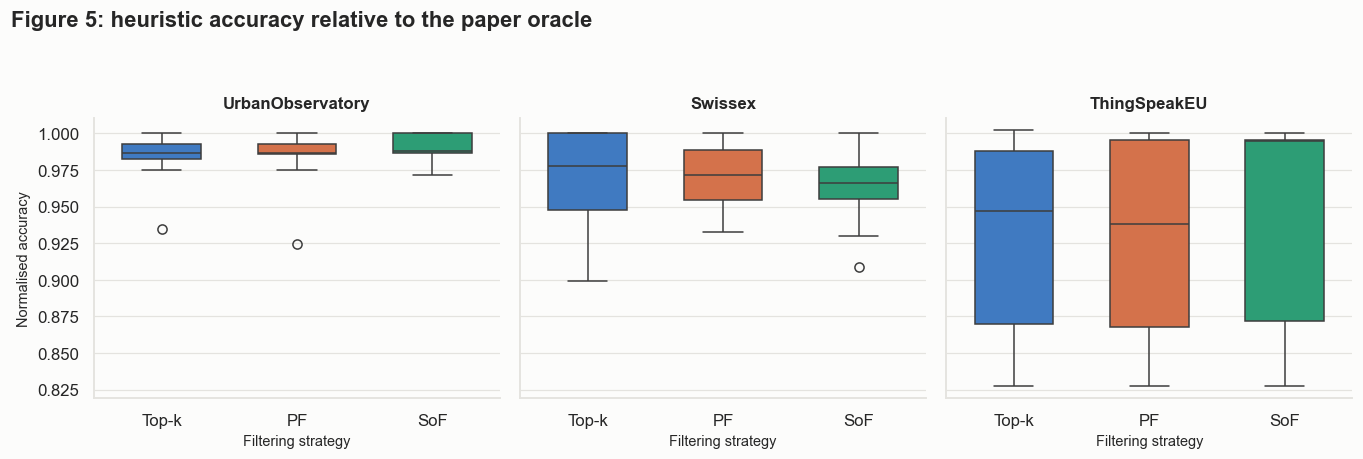

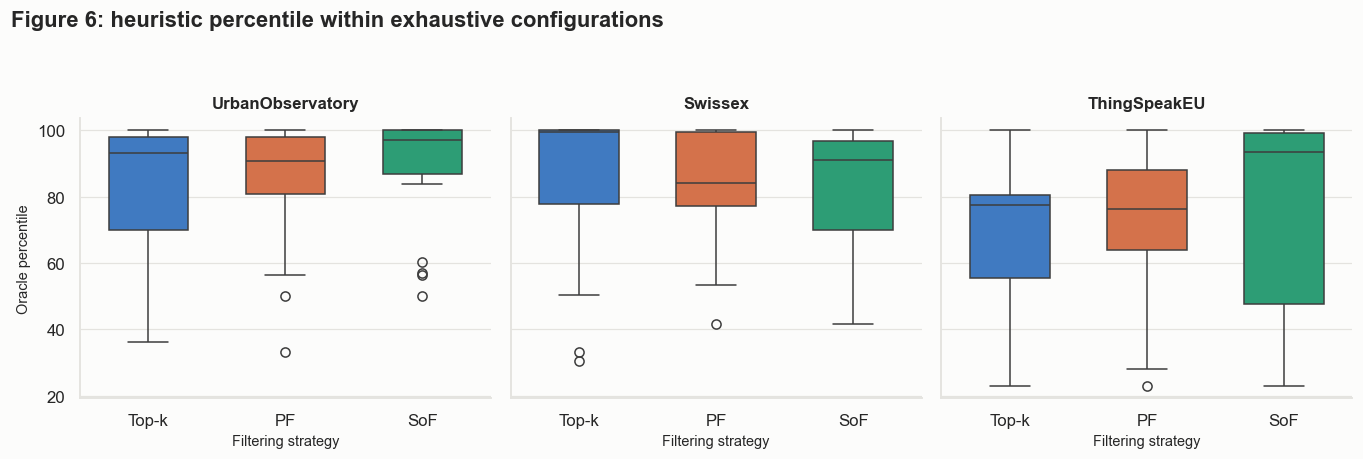

In [10]:
# compare normalised accuracy and exhaustive-search percentile
poolAnalysis = results['heuristicPoolAnalysis']
display(poolAnalysis.groupby(['Dataset', 'Heuristic'])[['NormalisedAccuracy', 'OraclePercentile']].agg(['mean', 'std', 'min', 'max']))
display(results['heuristicRepeatSensitivity'])
normalisedFigure = plotHeuristicDistributions(poolAnalysis, 'NormalisedAccuracy', 'Figure 5: heuristic accuracy relative to the paper oracle', 'Normalised accuracy')
percentileFigure = plotHeuristicDistributions(poolAnalysis, 'OraclePercentile', 'Figure 6: heuristic percentile within exhaustive configurations', 'Oracle percentile')
saveFigure(normalisedFigure, 'normalisedAccuracyDistributions')
saveFigure(percentileFigure, 'oraclePercentileDistributions')
plt.show()
plt.show()

### Findings

- The heuristic lands close to the oracle. Mean normalised accuracy is 0.986 to 0.990 on UrbObs, matching the paper's "1 to 2% below the optimum" and 0.968 to 0.972 on Swissex
- On ThingSpeak, SoF is the best strategy (0.951) as the paper reports, but its lead over Top-k (0.935) and PF (0.933) is under 2 points, smaller than the paper's "about 5%"
- The mean oracle percentile is 84 to 90 on UrbObs, in line with the paper's "around 80%, spanning down to 50%"
- The lowest ThingSpeak values (0.828) all come from pools that contain DDL-NLP but not RF, the same cluster the paper explains
- In 4 of 78 pool and dataset runs, the released selection code would repeat a classifier in the cascade.. I remove the repeat and the table above shows the accuracy with and without it
- Top-k can exceed 1.0 (maximum 1.002 on ThingSpeak) because the paper's oracle only searches SoF configurations

## Exp13: Error Analysis, Uncertainty and Runtime

The paper oracle is excluded from model recommendation. Per-class errors and fixed-test bootstrap intervals are calculated for the strongest valid method by macro F1

In [11]:
# retain detailed error evidence and the exact execution environment
errorOutputs = runErrorAnalysis(results['datasets'])
display(errorOutputs['perClassMetrics'])

# show each confusion matrix on its own without the other datasets' empty class columns
for _, matrix in errorOutputs['confusionMatrices'].groupby('Dataset', sort=False):
    display(matrix.dropna(axis=1, how='all'))
display(errorOutputs['macroF1BootstrapIntervals'])
versionTable = pd.DataFrame([
    {'Package': 'Python', 'Version': platform.python_version()},
    {'Package': 'NumPy', 'Version': np.__version__},
    {'Package': 'pandas', 'Version': pd.__version__},
    {'Package': 'SciPy', 'Version': scipy.__version__},
    {'Package': 'scikit-learn', 'Version': sklearn.__version__},
    {'Package': 'Matplotlib', 'Version': matplotlib.__version__},
    {'Package': 'Seaborn', 'Version': sns.__version__},
])
display(results['runtime'])
display(versionTable)

,Dataset,Method,Class,Precision,Recall,F1,Support
0,UrbanObservatory,Soft voting,0,0.950000,0.760000,0.844444,25
1,UrbanObservatory,Soft voting,1,0.916667,1.000000,0.956522,11
2,UrbanObservatory,Soft voting,2,0.972973,1.000000,0.986301,36
3,UrbanObservatory,Soft voting,3,0.700000,0.636364,0.666667,11
4,UrbanObservatory,Soft voting,4,1.000000,1.000000,1.000000,40
5,UrbanObservatory,Soft voting,5,1.000000,1.000000,1.000000,11
6,UrbanObservatory,Soft voting,6,0.666667,0.800000,0.727273,10
7,UrbanObservatory,Soft voting,7,1.000000,0.700000,0.823529,10
8,UrbanObservatory,Soft voting,8,1.000000,1.000000,1.000000,4
9,UrbanObservatory,Soft voting,9,0.875000,0.875000,0.875000,8


,Dataset,Method,ActualClass,Predicted_0,Predicted_1,Predicted_2,Predicted_3,Predicted_4,Predicted_5,Predicted_6,Predicted_7,Predicted_8,Predicted_9,Predicted_10,Predicted_11,Predicted_12,Predicted_13,Predicted_14,Predicted_15
0,UrbanObservatory,Soft voting,Actual_0,19,0,0,0,0,0,0,0,0,1,0,0.0,2.0,0.0,3.0,0.0
1,UrbanObservatory,Soft voting,Actual_1,0,11,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0
2,UrbanObservatory,Soft voting,Actual_2,0,0,36,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0
3,UrbanObservatory,Soft voting,Actual_3,0,0,0,7,0,0,4,0,0,0,0,0.0,0.0,0.0,0.0,0.0
4,UrbanObservatory,Soft voting,Actual_4,0,0,0,0,40,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0
5,UrbanObservatory,Soft voting,Actual_5,0,0,0,0,0,11,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0
6,UrbanObservatory,Soft voting,Actual_6,0,0,0,2,0,0,8,0,0,0,0,0.0,0.0,0.0,0.0,0.0
7,UrbanObservatory,Soft voting,Actual_7,0,0,0,0,0,0,0,7,0,0,3,0.0,0.0,0.0,0.0,0.0
8,UrbanObservatory,Soft voting,Actual_8,0,0,0,0,0,0,0,0,4,0,0,0.0,0.0,0.0,0.0,0.0
9,UrbanObservatory,Soft voting,Actual_9,0,0,1,0,0,0,0,0,0,7,0,0.0,0.0,0.0,0.0,0.0


,Dataset,Method,ActualClass,Predicted_0,Predicted_1,Predicted_2,Predicted_3,Predicted_4,Predicted_5,Predicted_6,Predicted_7,Predicted_8,Predicted_9,Predicted_10
16,Swissex,MACE Top-k,Actual_0,5,0,0,0,0,0,0,0,0,0,0
17,Swissex,MACE Top-k,Actual_1,0,8,0,1,0,0,1,0,0,0,0
18,Swissex,MACE Top-k,Actual_2,0,0,7,0,0,0,0,0,0,0,0
19,Swissex,MACE Top-k,Actual_3,0,0,0,3,0,0,0,3,0,0,0
20,Swissex,MACE Top-k,Actual_4,0,0,0,0,4,0,0,0,0,0,0
21,Swissex,MACE Top-k,Actual_5,1,1,0,0,1,7,0,0,0,0,0
22,Swissex,MACE Top-k,Actual_6,0,0,0,1,0,0,6,0,1,1,0
23,Swissex,MACE Top-k,Actual_7,0,0,0,1,0,1,0,20,0,0,1
24,Swissex,MACE Top-k,Actual_8,0,0,0,0,0,0,0,1,4,0,0
25,Swissex,MACE Top-k,Actual_9,0,0,0,0,0,1,0,0,0,10,0


,Dataset,Method,ActualClass,Predicted_0,Predicted_1,Predicted_2,Predicted_3,Predicted_4,Predicted_5,Predicted_6,...,Predicted_11,Predicted_12,Predicted_13,Predicted_14,Predicted_15,Predicted_16,Predicted_17,Predicted_18,Predicted_19,Predicted_20
27,ThingSpeakEU,MACE SoF,Actual_0,52,2,0,14,11,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
28,ThingSpeakEU,MACE SoF,Actual_1,1,128,0,1,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
29,ThingSpeakEU,MACE SoF,Actual_2,1,0,79,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30,ThingSpeakEU,MACE SoF,Actual_3,8,0,0,82,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
31,ThingSpeakEU,MACE SoF,Actual_4,4,1,0,2,94,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
32,ThingSpeakEU,MACE SoF,Actual_5,0,0,0,0,2,11,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
33,ThingSpeakEU,MACE SoF,Actual_6,0,1,0,0,0,0,11,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
34,ThingSpeakEU,MACE SoF,Actual_7,1,1,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
35,ThingSpeakEU,MACE SoF,Actual_8,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
36,ThingSpeakEU,MACE SoF,Actual_9,1,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,Dataset,Method,Mean,Lower,Upper
0,UrbanObservatory,Soft voting,0.879517,0.829214,0.922275
1,Swissex,MACE Top-k,0.823429,0.732534,0.898003
2,ThingSpeakEU,MACE SoF,0.792579,0.716577,0.874002


,Dataset,RuntimeSeconds,BruteForceIncluded
0,UrbanObservatory,60.23,True
1,Swissex,22.17,True
2,ThingSpeakEU,159.01,True


,Package,Version
0,Python,3.11.16
1,NumPy,2.4.4
2,pandas,3.0.2
3,SciPy,1.17.1
4,scikit-learn,1.8.0
5,Matplotlib,3.10.9
6,Seaborn,0.13.2


### Findings

- By macro F1, the strongest valid method is soft voting on UrbObs (88.5), MACE Top-k on Swissex (83.2) and MACE SoF on ThingSpeak (79.4)
- The 95% bootstrap interval for ThingSpeak macro F1 is wide (71.7 to 87.4) because several classes have only 1 to 5 test streams. Class 9 has a single test stream and is never predicted correctly and class 15 is recalled once in four
- ThingSpeak is the slowest dataset because the oracle evaluates 2,925 configurations on its 21 classes.. exact timings are in the runtime table and vary between machines

## Summary

| Paper item | Reproduced | Main result |
|---|---|---|
| Figure 3(b) standalone BOS | Yes | 18 of 24 within 6 points.. SVM and LR gaps come from unreleased tuning and unscaled features |
| Figure 3(a) time series | Partly | 1NN-ED and 1NN-DTW match on ThingSpeak and UrbObs.. BOPF, SDE and LTS were not released |
| DDL-NLP | Yes, exact | 73.2 vs 73.2 |
| Figure 4 top-k curves | Yes | Same dominance pattern.. Top-k value off by one on ties |
| Classifier selection | Yes, exact | Same order on all three datasets |
| Tables I and II, MACE rows | Yes | Accuracy within 0.6 in 8 of 9 cells, F1 within 0.3 in 8 of 9 |
| Tables I and II, baselines | Gaps explained | Best standalone mixes two runs, voting pool unstated, brute force is a test oracle |
| Figures 5 and 6 | Yes, qualitatively | Heuristics close to the oracle.. smaller strategy gap on ThingSpeak than reported |

## Reproduction boundary

- The released code's behaviour is kept separate from alternatives described only in the paper text
- Every selection step uses training data only, except the clearly labelled paper oracle
- All five pool classifiers are used for the main soft vote
- Classes removed by the cascade keep a score of exactly zero
- Notebook 3 tests leakage, robustness and the ambiguous implementation choices